In [11]:
# Triple-Stacked LSTM Implementation
# This model uses 3 LSTM layers to capture hierarchical temporal patterns
# at multiple levels of abstraction, approximating some benefits of HM-RNN
# without requiring as much data.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [12]:
# Load data
csv_path = "eth_hourly.csv"
df = pd.read_csv(csv_path)
df.head()

,Date,close,high,low,open,volume
0,2017-11-09,320.884003,329.451996,307.056000,308.644989,893249984
1,2017-11-10,299.252991,324.717987,294.541992,320.670990,885985984
2,2017-11-11,314.681000,319.453003,298.191986,298.585999,842300992
3,2017-11-12,307.907990,319.153015,298.513000,314.690002,1613479936
4,2017-11-13,316.716003,328.415009,307.024994,307.024994,1041889984


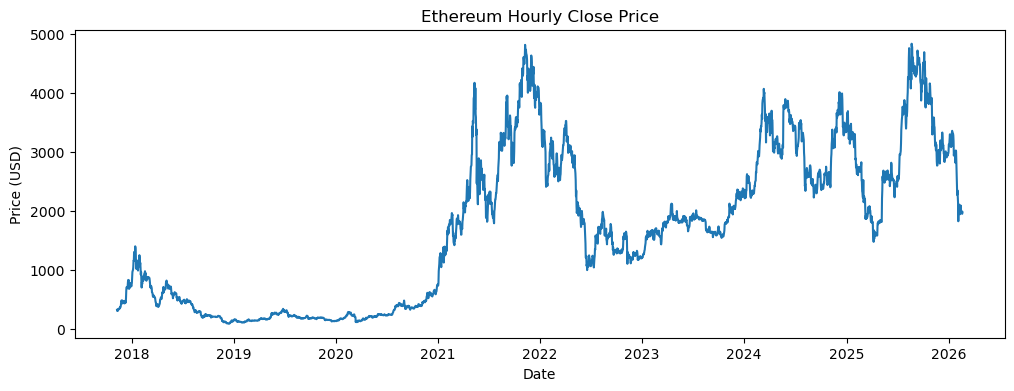

In [13]:
# Preprocess data
df["Date"] = pd.to_datetime(df["Date"])
series = df.sort_values("Date")

# Plot the close price
plt.figure(figsize=(12, 4))
plt.plot(series["Date"], series["close"])
plt.title("Ethereum Hourly Close Price")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.show()

In [14]:
# Convert the close column to a numpy array
close_values = series["close"].values.reshape(-1, 1)

# Calculate the number of training, validation, and test samples
n = len(close_values)
train_end = int(n * 0.80)
val_end   = int(n * 0.85)

# Create training, validation, and test sets
train_raw = close_values[:train_end]
val_raw   = close_values[train_end:val_end]
test_raw  = close_values[val_end:]

# Scale the data
scaler = MinMaxScaler()
train = scaler.fit_transform(train_raw)
val   = scaler.transform(val_raw)
test  = scaler.transform(test_raw)

# Check the shape of the data
train.shape, val.shape, test.shape

((2420, 1), (152, 1), (454, 1))

In [15]:
# Window size for historical data
WINDOW = 60

# Creates a window of data for the model to look at
def make_windows(data, window=60):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i])   # previous window days
        y.append(data[i])            # next day
    return np.array(X), np.array(y)

# Create windowed datasets
X_train, y_train = make_windows(train, WINDOW)
X_val,   y_val   = make_windows(val, WINDOW)
X_test,  y_test  = make_windows(test, WINDOW)

# Check the shape of the data
X_train.shape, y_train.shape

((2360, 60, 1), (2360, 1))

In [16]:
# Build the Triple-Stacked LSTM Model
# Layer 1 (128 units): Learns fine-grained, short-term patterns
# Layer 2 (64 units): Learns mid-level, more abstract patterns
# Layer 3 (32 units): Learns high-level, long-term patterns

model = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    
    # Layer 1: Fine-grained patterns (return_sequences=True to pass to next LSTM)
    layers.LSTM(128, return_sequences=True),
    layers.Dropout(0.2),
    
    # Layer 2: Mid-level patterns (return_sequences=True to pass to next LSTM)
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    
    # Layer 3: High-level patterns (return_sequences=False for final output)
    layers.LSTM(32),
    layers.Dropout(0.2),
    
    # Dense layers for final prediction
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

model.compile(
    optimizer='adam',  # Default Adam optimizer (learning_rate=0.001)
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 60, 128)        │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 60, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 128,929 (503.63 KB)

 Trainable params: 128,929 (503.63 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Train the model
# Hyperparameters matched to Parth's implementation for fair comparison
EPOCHS = 100
BATCH_SIZE = 32

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

print(f"\nTraining stopped at epoch {len(history.history['loss'])}")

Epoch 1/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 0.0114 - mae: 0.0643 - val_loss: 0.0024 - val_mae: 0.0404
Epoch 2/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0038 - mae: 0.0389 - val_loss: 0.0022 - val_mae: 0.0381
Epoch 3/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0032 - mae: 0.0353 - val_loss: 0.0023 - val_mae: 0.0398
Epoch 4/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0031 - mae: 0.0349 - val_loss: 0.0021 - val_mae: 0.0345
Epoch 5/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0028 - mae: 0.0335 - val_loss: 0.0018 - val_mae: 0.0322
Epoch 6/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0023 - mae: 0.0302 - val_loss: 0.0017 - val_mae: 0.0322
Epoch 7/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0020 - mae: 0.0291 - val_loss: 0.0019 - val_mae: 0.0316
Epoch 8/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0020 - mae: 0.0282 - val_loss: 0.0056 - val_mae: 0.0649
Epoch 9/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - lo

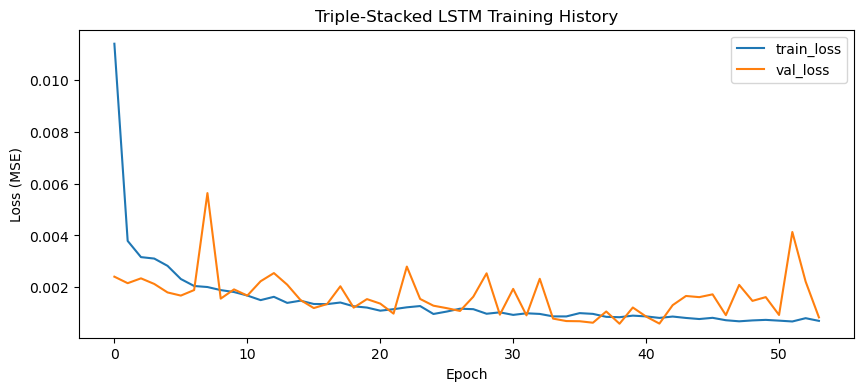

In [18]:
# Plot training history
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Triple-Stacked LSTM Training History")
plt.legend()
plt.show()

In [19]:
# Predict the test set
pred_test = model.predict(X_test)

# Inverse transform back to real USD prices
y_test_usd = scaler.inverse_transform(y_test)
pred_usd   = scaler.inverse_transform(pred_test)

# Calculate the MAE and RMSE
mae = mean_absolute_error(y_test_usd, pred_usd)
rmse = np.sqrt(mean_squared_error(y_test_usd, pred_usd))

print(f"Test MAE:  {mae:.2f} USD")
print(f"Test RMSE: {rmse:.2f} USD")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Test MAE:  128.14 USD
Test RMSE: 175.96 USD


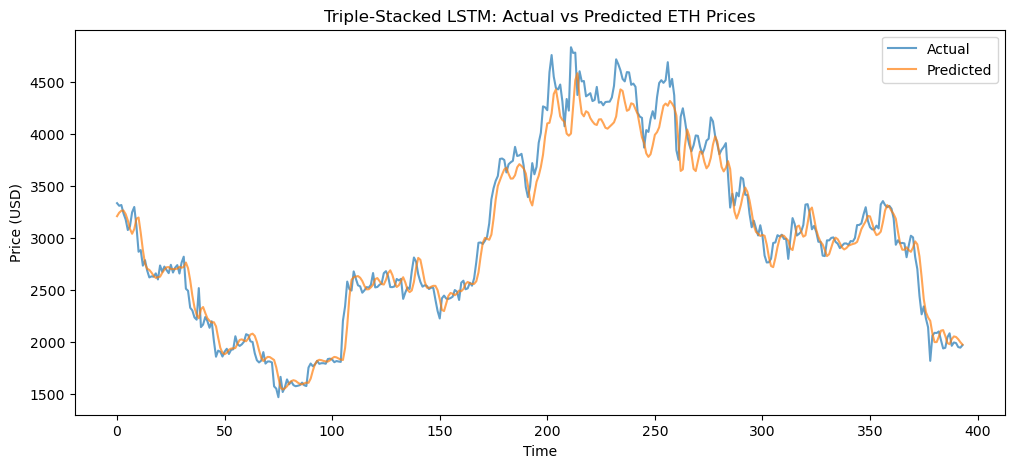

In [20]:
# Plot actual vs predicted prices
plt.figure(figsize=(12, 5))
plt.plot(y_test_usd, label="Actual", alpha=0.7)
plt.plot(pred_usd, label="Predicted", alpha=0.7)
plt.title("Triple-Stacked LSTM: Actual vs Predicted ETH Prices")
plt.xlabel("Time")
plt.ylabel("Price (USD)")
plt.legend()
plt.show()